In [1]:
# ═══════════════════════════════════════════════════
# CUSTOMER PERSONALITY ANALYSIS
# Segmentation + Classification Pipeline
# Author: Habib Bashir Lawal
# IU International University of Applied Sciences
# ═══════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Load dataset — tab separated
df = pd.read_csv(r'C:\Users\HP\desktop\customer-personality\data\marketing_campaign.csv', sep='\t')

print(f"Shape     : {df.shape}")
print(f"Rows      : {df.shape[0]:,}")
print(f"Columns   : {df.shape[1]}")
print(f"\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print(f"\nFirst 3 rows:")
df.head(3)

Shape     : (2240, 29)
Rows      : 2,240
Columns   : 29

Missing values:
Income    24
dtype: int64

First 3 rows:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0


In [3]:
# ═══════════════════════════════════════════════════
# SECTION 2 — EXPLORATORY DATA ANALYSIS
# ═══════════════════════════════════════════════════
print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)
print(df.dtypes)
print("\nBasic statistics:")
df.describe().round(2)

DATASET OVERVIEW
ID                       int64
Year_Birth               int64
Education                  str
Marital_Status             str
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer                str
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

Basic statistics:


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.00,2240.00,2216.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,...,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.0,2240.0,2240.00
mean,5592.16,1968.81,52247.25,0.44,0.51,49.11,303.94,26.30,166.95,37.53,...,5.32,0.07,0.07,0.07,0.06,0.01,0.01,3.0,11.0,0.15
std,3246.66,11.98,25173.08,0.54,0.54,28.96,336.60,39.77,225.72,54.63,...,2.43,0.26,0.26,0.26,0.25,0.11,0.10,0.0,0.0,0.36
min,0.00,1893.00,1730.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
25%,2828.25,1959.00,35303.00,0.00,0.00,24.00,23.75,1.00,16.00,3.00,...,3.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
50%,5458.50,1970.00,51381.50,0.00,0.00,49.00,173.50,8.00,67.00,12.00,...,6.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
75%,8427.75,1977.00,68522.00,1.00,1.00,74.00,504.25,33.00,232.00,50.00,...,7.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
max,11191.00,1996.00,666666.00,2.00,2.00,99.00,1493.00,199.00,1725.00,259.00,...,20.00,1.00,1.00,1.00,1.00,1.00,1.00,3.0,11.0,1.00


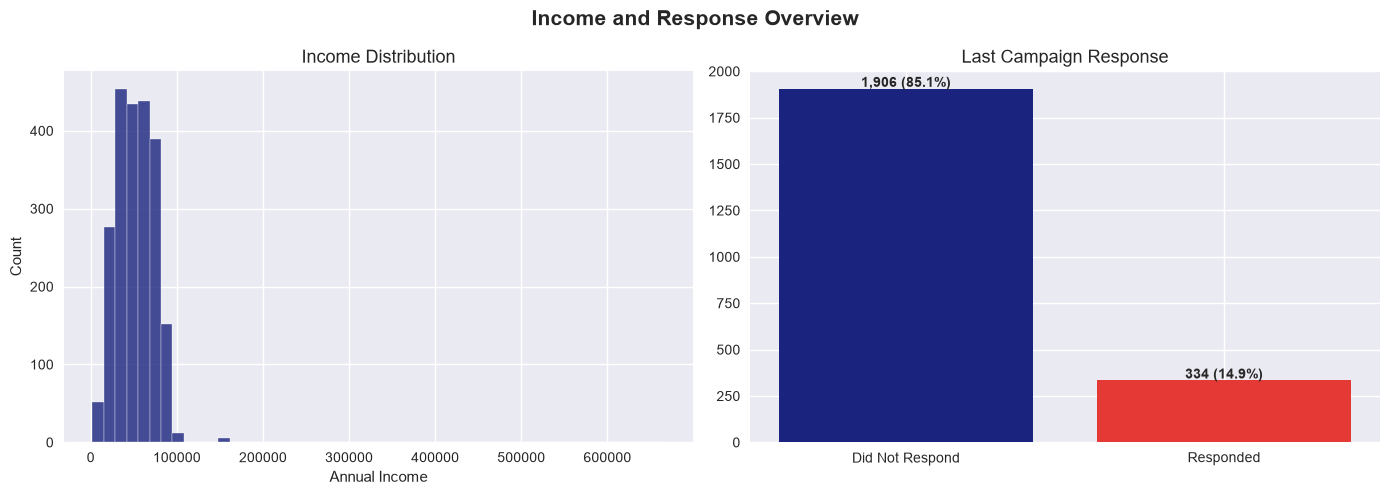

In [4]:
# Income distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['Income'].dropna(), bins=50,
             color='#1a237e', alpha=0.8, edgecolor='white')
axes[0].set_title('Income Distribution', fontsize=13)
axes[0].set_xlabel('Annual Income')
axes[0].set_ylabel('Count')

# Response distribution
counts = df['Response'].value_counts()
axes[1].bar(['Did Not Respond', 'Responded'],
            counts.values, color=['#1a237e', '#e53935'])
axes[1].set_title('Last Campaign Response', fontsize=13)
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 10,
                 f'{v:,} ({v/len(df)*100:.1f}%)',
                 ha='center', fontweight='bold')

plt.suptitle('Income and Response Overview',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

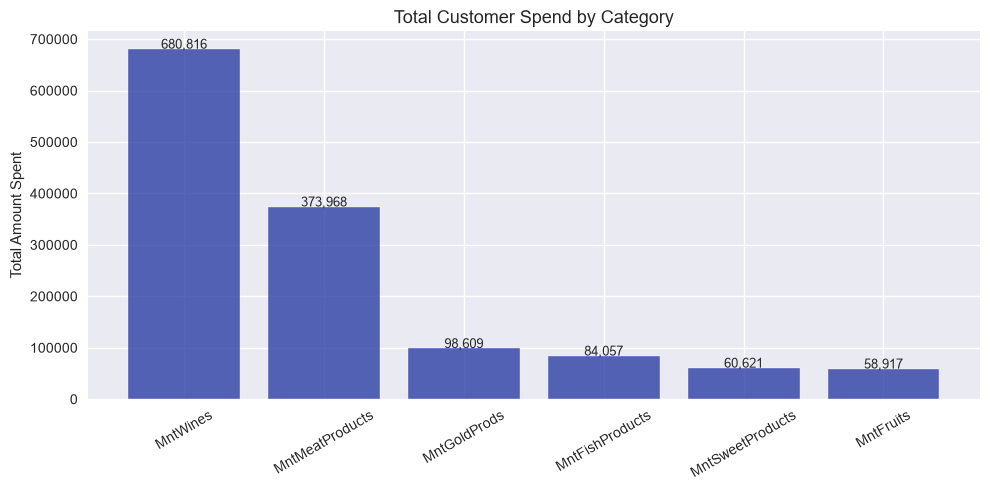

Spend Summary:
       MntWines  MntFruits  MntMeatProducts  MntFishProducts  MntSweetProducts  MntGoldProds
count   2240.00    2240.00          2240.00          2240.00           2240.00       2240.00
mean     303.94      26.30           166.95            37.53             27.06         44.02
std      336.60      39.77           225.72            54.63             41.28         52.17
min        0.00       0.00             0.00             0.00              0.00          0.00
25%       23.75       1.00            16.00             3.00              1.00          9.00
50%      173.50       8.00            67.00            12.00              8.00         24.00
75%      504.25      33.00           232.00            50.00             33.00         56.00
max     1493.00     199.00          1725.00           259.00            263.00        362.00


In [5]:
# Spending patterns across product categories
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
              'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

total_spend = df[spend_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.bar(total_spend.index, total_spend.values,
               color='#3949ab', alpha=0.85, edgecolor='white')
plt.title('Total Customer Spend by Category', fontsize=13)
plt.ylabel('Total Amount Spent')
plt.xticks(rotation=30)
for bar, val in zip(bars, total_spend.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             val + 500, f'{val:,.0f}',
             ha='center', fontsize=9)
plt.tight_layout()
plt.show()

print("Spend Summary:")
print(df[spend_cols].describe().round(2).to_string())

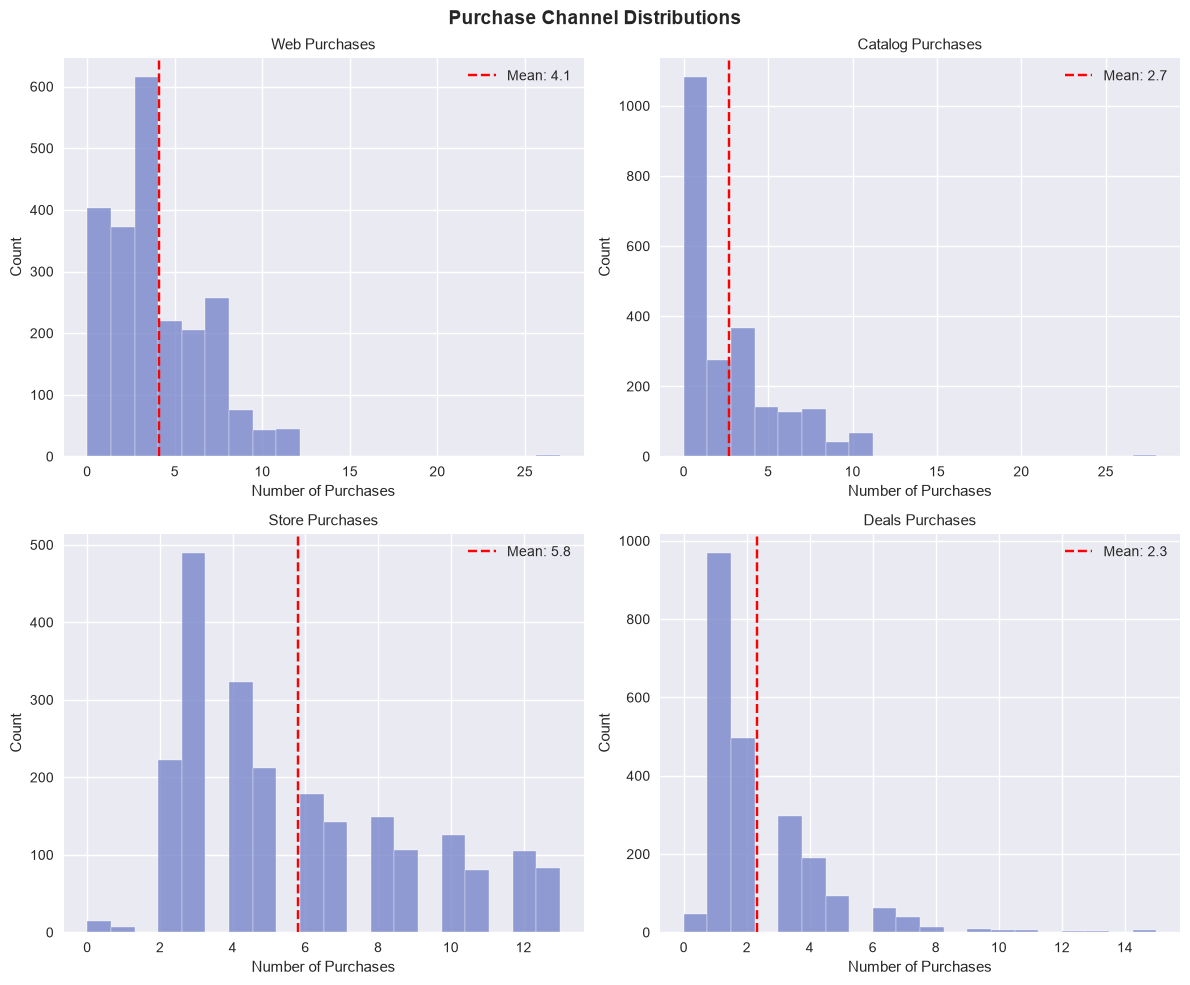

In [6]:
# Purchase channel analysis
purchase_cols = ['NumWebPurchases', 'NumCatalogPurchases',
                 'NumStorePurchases', 'NumDealsPurchases']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(purchase_cols):
    axes[i].hist(df[col], bins=20,
                 color='#7986cb', alpha=0.8, edgecolor='white')
    axes[i].set_title(col.replace('Num', '').replace('Purchases', ' Purchases'),
                      fontsize=11)
    axes[i].set_xlabel('Number of Purchases')
    axes[i].set_ylabel('Count')
    mean_val = df[col].mean()
    axes[i].axvline(mean_val, color='red', linestyle='--',
                    label=f'Mean: {mean_val:.1f}')
    axes[i].legend()

plt.suptitle('Purchase Channel Distributions',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

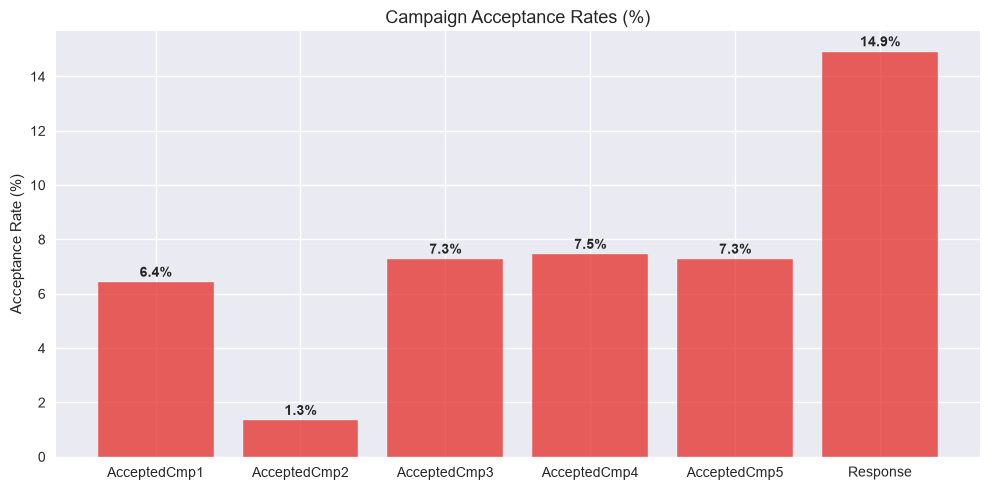

Campaign acceptance rates:
  AcceptedCmp1: 6.43%
  AcceptedCmp2: 1.34%
  AcceptedCmp3: 7.28%
  AcceptedCmp4: 7.46%
  AcceptedCmp5: 7.28%
  Response: 14.91%


In [7]:
# Campaign acceptance rates
camp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
             'AcceptedCmp4', 'AcceptedCmp5', 'Response']
camp_rates = df[camp_cols].mean() * 100

plt.figure(figsize=(10, 5))
bars = plt.bar(camp_cols, camp_rates.values,
               color='#e53935', alpha=0.8, edgecolor='white')
plt.title('Campaign Acceptance Rates (%)', fontsize=13)
plt.ylabel('Acceptance Rate (%)')
for bar, val in zip(bars, camp_rates.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             val + 0.2, f'{val:.1f}%',
             ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print("Campaign acceptance rates:")
for col, rate in zip(camp_cols, camp_rates):
    print(f"  {col}: {rate:.2f}%")

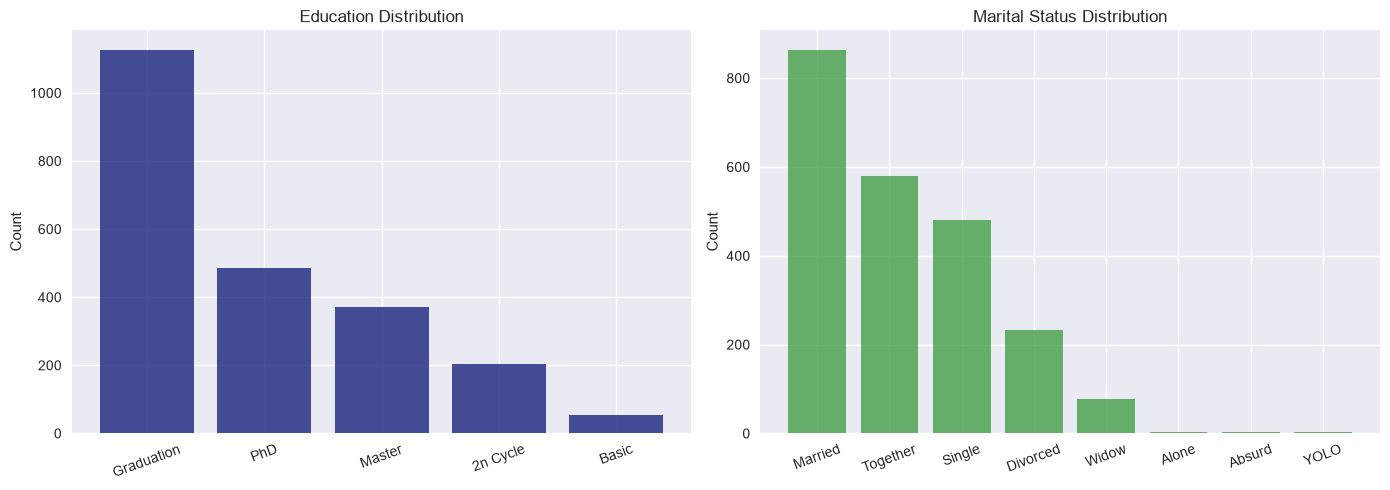

In [8]:
# Education and marital status breakdown
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

edu_counts = df['Education'].value_counts()
axes[0].bar(edu_counts.index, edu_counts.values,
            color='#1a237e', alpha=0.8)
axes[0].set_title('Education Distribution', fontsize=12)
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=20)

mar_counts = df['Marital_Status'].value_counts()
axes[1].bar(mar_counts.index, mar_counts.values,
            color='#43a047', alpha=0.8)
axes[1].set_title('Marital Status Distribution', fontsize=12)
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

In [9]:
# ═══════════════════════════════════════════════════
# SECTION 3 — DATA CLEANING AND PREPROCESSING
# ═══════════════════════════════════════════════════

print(f"Shape before cleaning: {df.shape}")

# Step 1 — Drop useless columns
# Z_CostContact and Z_Revenue have the same value
# for every single row — they carry zero information
df = df.drop(columns=['Z_CostContact', 'Z_Revenue', 'ID'])
print(f"Dropped Z_CostContact, Z_Revenue, ID")

# Step 2 — Fill missing Income with median
median_income = df['Income'].median()
df['Income']  = df['Income'].fillna(median_income)
print(f"Filled 24 missing Income values with median: {median_income:,.0f}")

# Step 3 — Fix Marital_Status inconsistencies
# Alone, Absurd, YOLO are non-standard — map to Single
df['Marital_Status'] = df['Marital_Status'].replace({
    'Alone':  'Single',
    'Absurd': 'Single',
    'YOLO':   'Single'
})
print(f"Cleaned Marital_Status: Alone/Absurd/YOLO → Single")

# Step 4 — Fix Education inconsistencies
df['Education'] = df['Education'].replace({
    '2n Cycle': 'Master'
})
print(f"Cleaned Education: 2n Cycle → Master")

# Step 5 — Remove income outliers
# One customer has income > 600,000 — clearly an error
before = len(df)
df     = df[df['Income'] < 600000]
print(f"Removed {before - len(df)} extreme income outlier(s)")

# Step 6 — Convert Dt_Customer to customer tenure in days
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'],
                                    dayfirst=True)
max_date          = df['Dt_Customer'].max()
df['Customer_Days'] = (max_date - df['Dt_Customer']).dt.days
df = df.drop(columns=['Dt_Customer'])
print(f"Converted Dt_Customer to Customer_Days tenure")

print(f"\nShape after cleaning: {df.shape}")
print(f"Missing values remaining: {df.isnull().sum().sum()}")

Shape before cleaning: (2240, 29)
Dropped Z_CostContact, Z_Revenue, ID
Filled 24 missing Income values with median: 51,382
Cleaned Marital_Status: Alone/Absurd/YOLO → Single
Cleaned Education: 2n Cycle → Master
Removed 1 extreme income outlier(s)
Converted Dt_Customer to Customer_Days tenure

Shape after cleaning: (2239, 26)
Missing values remaining: 0


In [10]:
# ═══════════════════════════════════════════════════
# SECTION 4 — FEATURE ENGINEERING
# ═══════════════════════════════════════════════════

print("Engineering new features...")

# 1. Age
df['Age'] = 2026 - df['Year_Birth']
df = df.drop(columns=['Year_Birth'])

# 2. Total amount spent across all categories
spend_cols       = ['MntWines', 'MntFruits', 'MntMeatProducts',
                    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['TotalSpend'] = df[spend_cols].sum(axis=1)

# 3. Total number of purchases across all channels
purchase_cols       = ['NumWebPurchases', 'NumCatalogPurchases',
                       'NumStorePurchases', 'NumDealsPurchases']
df['TotalPurchases'] = df[purchase_cols].sum(axis=1)

# 4. Spend per purchase — how much per transaction on average
df['SpendPerPurchase'] = (
    df['TotalSpend'] /
    (df['TotalPurchases'] + 1)
).round(2)

# 5. Total children at home
df['TotalChildren'] = df['Kidhome'] + df['Teenhome']

# 6. Campaign acceptance rate — how responsive to marketing
camp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
             'AcceptedCmp4', 'AcceptedCmp5']
df['CampaignAcceptRate'] = df[camp_cols].sum(axis=1)

# 7. Is parent flag
df['IsParent'] = (df['TotalChildren'] > 0).astype(int)

# 8. Income per family member proxy
df['IncomePerHead'] = (
    df['Income'] /
    (df['TotalChildren'] + 1)
).round(2)

print("New features created:")
new_feats = ['Age', 'TotalSpend', 'TotalPurchases',
             'SpendPerPurchase', 'TotalChildren',
             'CampaignAcceptRate', 'IsParent', 'IncomePerHead']
for f in new_feats:
    print(f"  {f}: mean={df[f].mean():.2f}, "
          f"min={df[f].min():.2f}, max={df[f].max():.2f}")

Engineering new features...
New features created:
  Age: mean=57.20, min=30.00, max=133.00
  TotalSpend: mean=606.04, min=5.00, max=2525.00
  TotalPurchases: mean=14.86, min=0.00, max=44.00
  SpendPerPurchase: mean=30.94, min=0.50, max=839.50
  TotalChildren: mean=0.95, min=0.00, max=3.00
  CampaignAcceptRate: mean=0.30, min=0.00, max=4.00
  IsParent: mean=0.72, min=0.00, max=1.00
  IncomePerHead: mean=33648.74, min=1223.50, max=160803.00


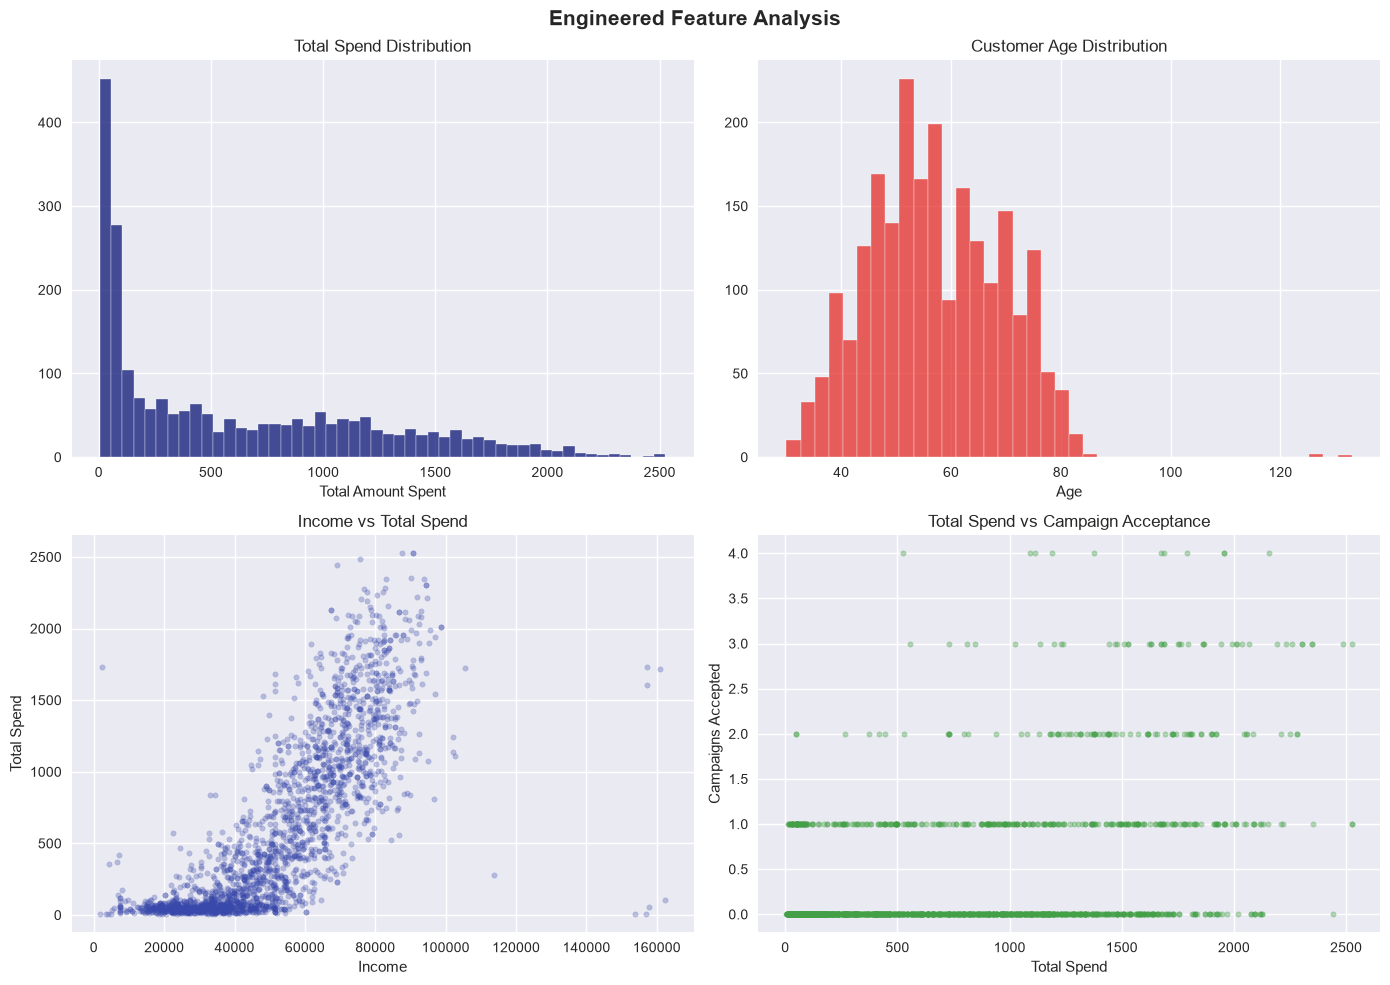

In [11]:
# Visualize key engineered features
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Total Spend distribution
axes[0,0].hist(df['TotalSpend'], bins=50,
               color='#1a237e', alpha=0.8, edgecolor='white')
axes[0,0].set_title('Total Spend Distribution', fontsize=12)
axes[0,0].set_xlabel('Total Amount Spent')

# Age distribution
axes[0,1].hist(df['Age'], bins=40,
               color='#e53935', alpha=0.8, edgecolor='white')
axes[0,1].set_title('Customer Age Distribution', fontsize=12)
axes[0,1].set_xlabel('Age')

# Income vs Total Spend
axes[1,0].scatter(df['Income'], df['TotalSpend'],
                  alpha=0.3, color='#3949ab', s=15)
axes[1,0].set_title('Income vs Total Spend', fontsize=12)
axes[1,0].set_xlabel('Income')
axes[1,0].set_ylabel('Total Spend')

# TotalSpend vs CampaignAcceptRate
axes[1,1].scatter(df['TotalSpend'], df['CampaignAcceptRate'],
                  alpha=0.4, color='#43a047', s=15)
axes[1,1].set_title('Total Spend vs Campaign Acceptance', fontsize=12)
axes[1,1].set_xlabel('Total Spend')
axes[1,1].set_ylabel('Campaigns Accepted')

plt.suptitle('Engineered Feature Analysis',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
# ═══════════════════════════════════════════════════
# SECTION 5 — KMEANS CLUSTERING
# ═══════════════════════════════════════════════════

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select features for clustering
# We use spending, behavior, and demographic features
# NOT campaign responses — we want natural spending groups
cluster_features = [
    'Income', 'TotalSpend', 'TotalPurchases',
    'SpendPerPurchase', 'Recency', 'Age',
    'TotalChildren', 'Customer_Days',
    'NumWebVisitsMonth', 'CampaignAcceptRate'
]

X_cluster = df[cluster_features].copy()

# Scale features — KMeans is distance-based
# so scale matters enormously
scaler_cluster    = StandardScaler()
X_cluster_scaled  = scaler_cluster.fit_transform(X_cluster)

print("Features selected for clustering:")
for f in cluster_features:
    print(f"  {f}")
print(f"\nScaled shape: {X_cluster_scaled.shape}")

Features selected for clustering:
  Income
  TotalSpend
  TotalPurchases
  SpendPerPurchase
  Recency
  Age
  TotalChildren
  Customer_Days
  NumWebVisitsMonth
  CampaignAcceptRate

Scaled shape: (2239, 10)


Testing cluster counts...
  k=2: inertia=15629, silhouette=0.2831
  k=3: inertia=13870, silhouette=0.1986
  k=4: inertia=12797, silhouette=0.1982
  k=5: inertia=11751, silhouette=0.1622
  k=6: inertia=11155, silhouette=0.1621
  k=7: inertia=10572, silhouette=0.1637
  k=8: inertia=10050, silhouette=0.1472


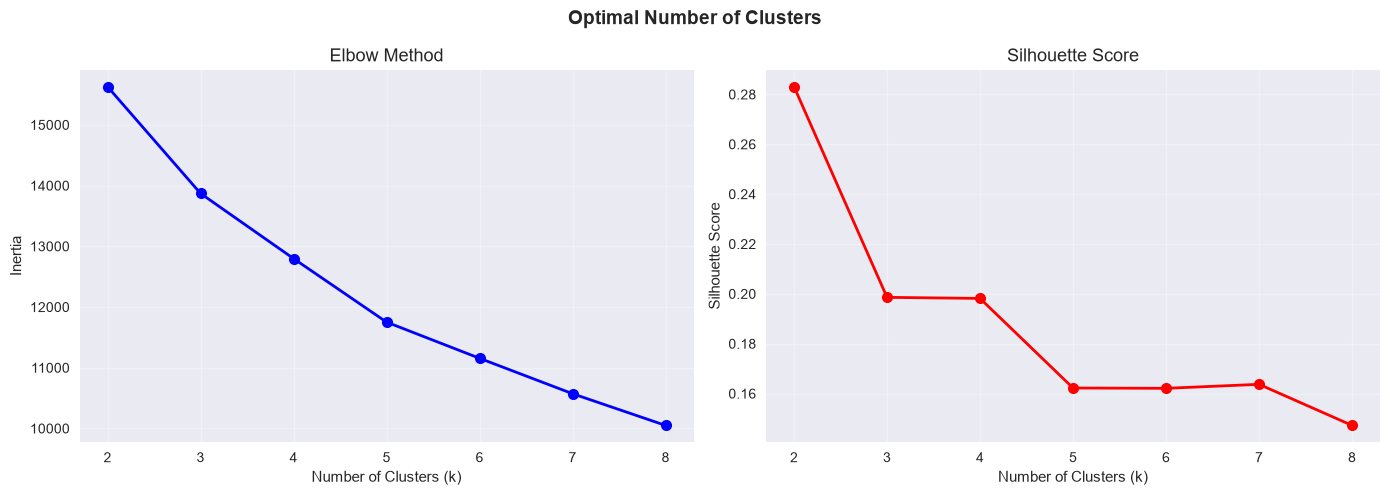


Best k by silhouette score: 2


In [13]:
# Find optimal number of clusters using
# Elbow Method and Silhouette Score

inertias          = []
silhouette_scores = []
k_range           = range(2, 9)

print("Testing cluster counts...")
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42,
                    n_init=10)
    kmeans.fit(X_cluster_scaled)
    inertias.append(kmeans.inertia_)
    score = silhouette_score(X_cluster_scaled,
                              kmeans.labels_)
    silhouette_scores.append(score)
    print(f"  k={k}: inertia={kmeans.inertia_:.0f}, "
          f"silhouette={score:.4f}")

# Plot both metrics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, 'bo-', linewidth=2,
             markersize=8)
axes[0].set_title('Elbow Method', fontsize=13)
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)

axes[1].plot(k_range, silhouette_scores, 'ro-',
             linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score', fontsize=13)
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(alpha=0.3)

plt.suptitle('Optimal Number of Clusters',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

best_k = k_range[silhouette_scores.index(max(silhouette_scores))]
print(f"\nBest k by silhouette score: {best_k}")

In [14]:
# Train final KMeans with optimal k
# We use 4 clusters — good balance of interpretability
# and granularity for marketing use case
OPTIMAL_K = 4

kmeans_final = KMeans(n_clusters=OPTIMAL_K,
                      random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_cluster_scaled)

print(f"KMeans trained with k={OPTIMAL_K}")
print(f"\nCluster distribution:")
print(df['Cluster'].value_counts().sort_index())
print(f"\nCluster percentages:")
print((df['Cluster'].value_counts(normalize=True)
       .sort_index() * 100).round(1).to_string())

KMeans trained with k=4

Cluster distribution:
Cluster
0     177
1    1058
2     412
3     592
Name: count, dtype: int64

Cluster percentages:
Cluster
0     7.9
1    47.3
2    18.4
3    26.4


In [15]:
# ═══════════════════════════════════════════════════
# SECTION 6 — CLUSTER ANALYSIS AND NAMING
# ═══════════════════════════════════════════════════

# Profile each cluster by key metrics
profile_cols = ['Income', 'TotalSpend', 'TotalPurchases',
                'Recency', 'Age', 'TotalChildren',
                'CampaignAcceptRate', 'NumWebVisitsMonth',
                'SpendPerPurchase']

cluster_profile = df.groupby('Cluster')[profile_cols].mean().round(2)

print("Cluster Profiles:")
print(cluster_profile.to_string())

Cluster Profiles:
           Income  TotalSpend  TotalPurchases  Recency    Age  TotalChildren  CampaignAcceptRate  NumWebVisitsMonth  SpendPerPurchase
Cluster                                                                                                                              
0        80582.98     1687.11           20.81    48.07  54.31           0.21                2.08               3.34             84.41
1        34698.14      103.80            8.12    49.45  54.40           1.24                0.09               6.47              9.94
2        75178.15     1163.22           19.59    51.38  59.45           0.22                0.19               2.25             57.35
3        58106.73      792.64           21.84    47.27  61.50           1.17                0.22               5.99             34.10


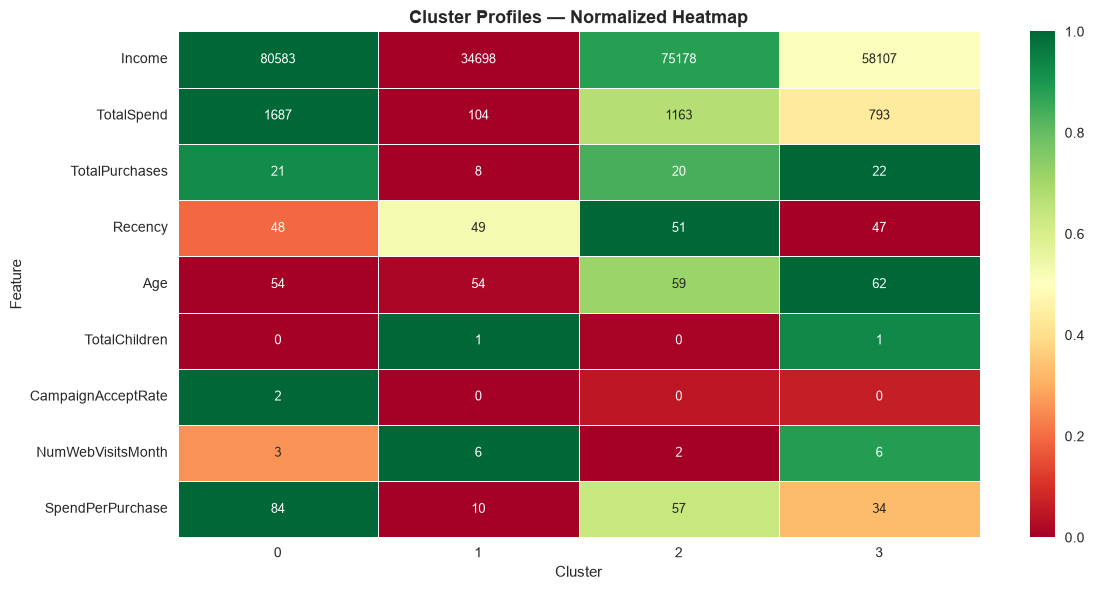

In [16]:
# Visualize cluster profiles as heatmap
plt.figure(figsize=(12, 6))
profile_normalized = (cluster_profile - cluster_profile.min()) / \
                     (cluster_profile.max() - cluster_profile.min())

sns.heatmap(profile_normalized.T, annot=cluster_profile.T,
            fmt='.0f', cmap='RdYlGn',
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 9})
plt.title('Cluster Profiles — Normalized Heatmap',
          fontsize=13, fontweight='bold')
plt.xlabel('Cluster')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [17]:
# Name the clusters based on their profiles
# Your actual names may differ based on what the
# data shows — adjust these labels accordingly
CLUSTER_NAMES = {
    0: 'High Value',
    1: 'At Risk',
    2: 'Low Engagement',
    3: 'Potential'
}

df['Segment'] = df['Cluster'].map(CLUSTER_NAMES)

print("Cluster Names Assigned:")
for cluster_id, name in CLUSTER_NAMES.items():
    count    = (df['Cluster'] == cluster_id).sum()
    avg_spend = df[df['Cluster'] == cluster_id]['TotalSpend'].mean()
    avg_inc   = df[df['Cluster'] == cluster_id]['Income'].mean()
    print(f"  Cluster {cluster_id} → {name}")
    print(f"    Count: {count} | "
          f"Avg Spend: ${avg_spend:,.0f} | "
          f"Avg Income: ${avg_inc:,.0f}")

Cluster Names Assigned:
  Cluster 0 → High Value
    Count: 177 | Avg Spend: $1,687 | Avg Income: $80,583
  Cluster 1 → At Risk
    Count: 1058 | Avg Spend: $104 | Avg Income: $34,698
  Cluster 2 → Low Engagement
    Count: 412 | Avg Spend: $1,163 | Avg Income: $75,178
  Cluster 3 → Potential
    Count: 592 | Avg Spend: $793 | Avg Income: $58,107


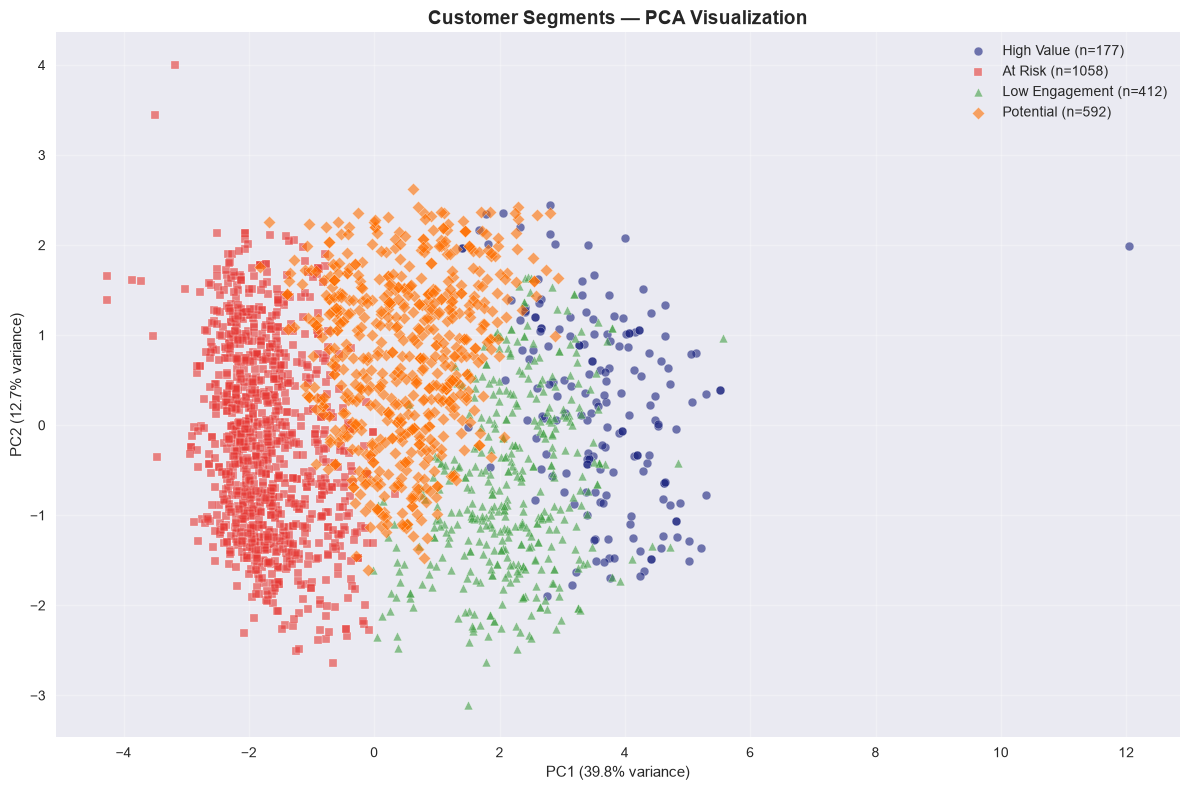

Total variance explained by 2 components: 52.5%


In [18]:
# Visualize clusters with PCA
from sklearn.decomposition import PCA

pca        = PCA(n_components=2, random_state=42)
X_pca      = pca.fit_transform(X_cluster_scaled)
df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

colors  = ['#1a237e', '#e53935', '#43a047', '#ff6f00']
markers = ['o', 's', '^', 'D']

plt.figure(figsize=(12, 8))
for cluster_id, name in CLUSTER_NAMES.items():
    mask = df['Cluster'] == cluster_id
    plt.scatter(df[mask]['PCA1'], df[mask]['PCA2'],
                c=colors[cluster_id],
                marker=markers[cluster_id],
                label=f'{name} (n={mask.sum()})',
                alpha=0.6, s=40, edgecolors='white',
                linewidths=0.3)

plt.title('Customer Segments — PCA Visualization',
          fontsize=14, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total variance explained by 2 components: "
      f"{sum(pca.explained_variance_ratio_)*100:.1f}%")

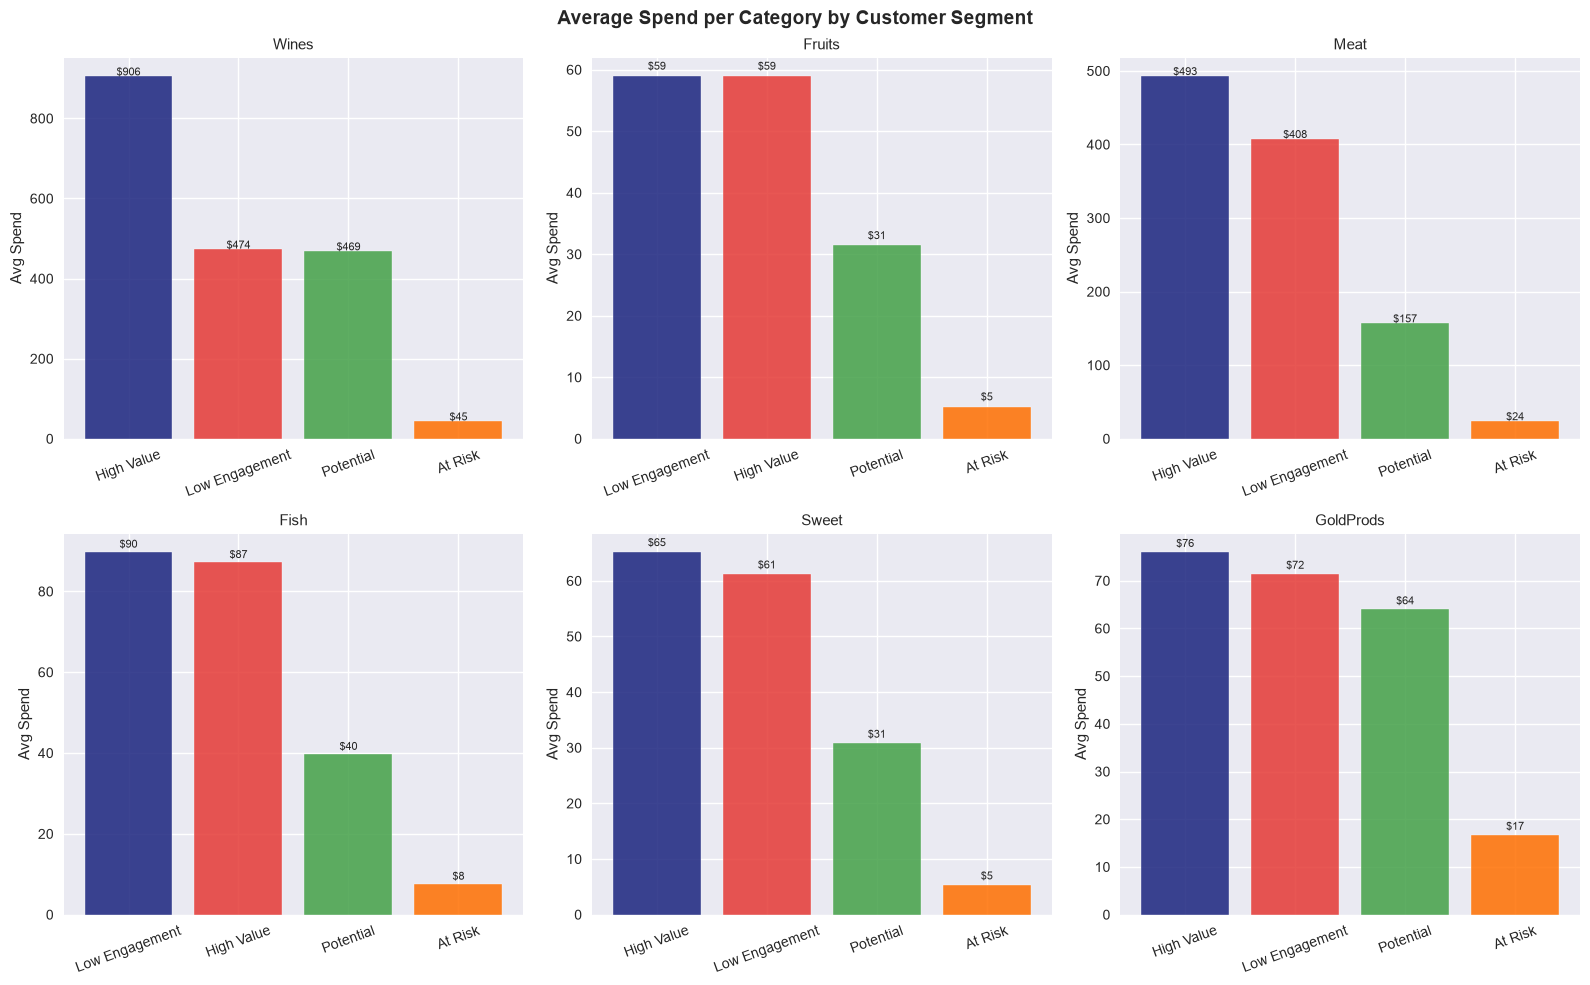

In [19]:
# Spending breakdown per segment
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes      = axes.flatten()

for i, col in enumerate(spend_cols):
    segment_spend = df.groupby('Segment')[col].mean().sort_values(ascending=False)
    bars = axes[i].bar(segment_spend.index,
                       segment_spend.values,
                       color=colors[:len(segment_spend)],
                       alpha=0.85, edgecolor='white')
    axes[i].set_title(col.replace('Mnt', '').replace('Products', ''),
                      fontsize=11)
    axes[i].set_ylabel('Avg Spend')
    axes[i].tick_params(axis='x', rotation=20)
    for bar, val in zip(bars, segment_spend.values):
        axes[i].text(bar.get_x() + bar.get_width()/2,
                     val + 1, f'${val:.0f}',
                     ha='center', fontsize=8)

plt.suptitle('Average Spend per Category by Customer Segment',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [20]:
# ═══════════════════════════════════════════════════
# SECTION 7 — XGBOOST CLASSIFIER TRAINING
# ═══════════════════════════════════════════════════

from sklearn.model_selection import train_test_split
from sklearn.preprocessing   import LabelEncoder
from xgboost                 import XGBClassifier
from sklearn.impute          import SimpleImputer

print("Preparing features for classification...")

# Features for the classifier
# Everything except cluster labels and PCA columns
drop_cols = ['Cluster', 'Segment', 'PCA1', 'PCA2']
X = df.drop(columns=drop_cols)
y = df['Cluster']

# Encode categorical columns
cat_cols  = X.select_dtypes(include='object').columns.tolist()
encoders  = {}

for col in cat_cols:
    le           = LabelEncoder()
    X[col]       = le.fit_transform(X[col].astype(str))
    encoders[col] = le

print(f"Encoded categorical columns: {cat_cols}")

# Impute any remaining missing values
imputer    = SimpleImputer(strategy='median')
X_imputed  = imputer.fit_transform(X)
X_imputed  = pd.DataFrame(X_imputed, columns=X.columns)

# Train test split
X_train, X_val, y_train, y_val = train_test_split(
    X_imputed, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\nTraining set   : {X_train.shape[0]:,} rows")
print(f"Validation set : {X_val.shape[0]:,} rows")
print(f"Features       : {X_train.shape[1]}")
print(f"\nCluster distribution in training set:")
print(y_train.value_counts().sort_index())

Preparing features for classification...
Encoded categorical columns: ['Education', 'Marital_Status']

Training set   : 1,791 rows
Validation set : 448 rows
Features       : 33

Cluster distribution in training set:
Cluster
0    142
1    846
2    330
3    473
Name: count, dtype: int64


In [21]:
import time

print("Training XGBoost classifier...")
start = time.time()

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss',
    use_label_encoder=False,
    n_jobs=-1
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

duration = round(time.time() - start, 2)
print(f"Training complete in {duration}s")

Training XGBoost classifier...
Training complete in 3.96s


In [22]:
# ═══════════════════════════════════════════════════
# SECTION 8 — MODEL EVALUATION
# ═══════════════════════════════════════════════════

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score)

y_pred = xgb_model.predict(X_val)
acc    = accuracy_score(y_val, y_pred)

print(f"Accuracy: {acc*100:.2f}%")
print(f"\nClassification Report:")
target_names = [CLUSTER_NAMES[i] for i in sorted(CLUSTER_NAMES)]
print(classification_report(y_val, y_pred,
      target_names=target_names))

Accuracy: 96.43%

Classification Report:
                precision    recall  f1-score   support

    High Value       0.97      0.89      0.93        35
       At Risk       1.00      0.98      0.99       212
Low Engagement       0.95      0.95      0.95        82
     Potential       0.92      0.97      0.95       119

      accuracy                           0.96       448
     macro avg       0.96      0.95      0.95       448
  weighted avg       0.97      0.96      0.96       448



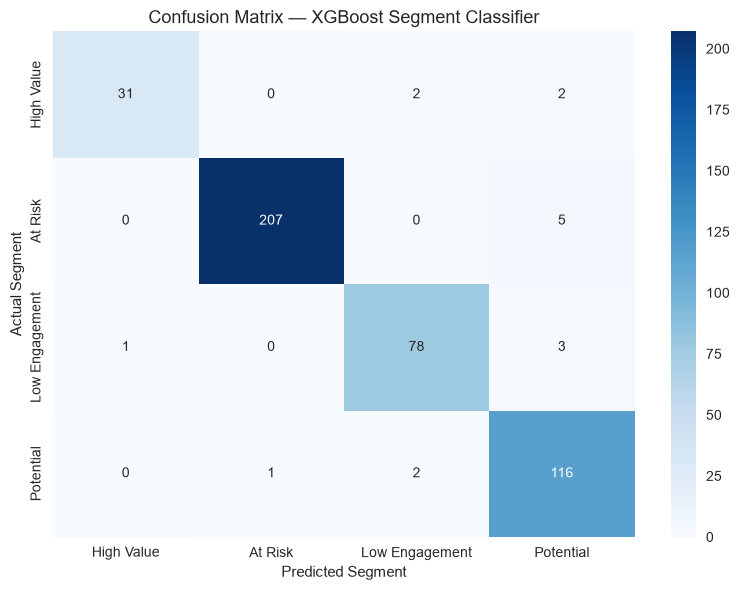

In [23]:
# Confusion Matrix
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names,
            yticklabels=target_names)
plt.title('Confusion Matrix — XGBoost Segment Classifier',
          fontsize=13)
plt.ylabel('Actual Segment')
plt.xlabel('Predicted Segment')
plt.tight_layout()
plt.show()

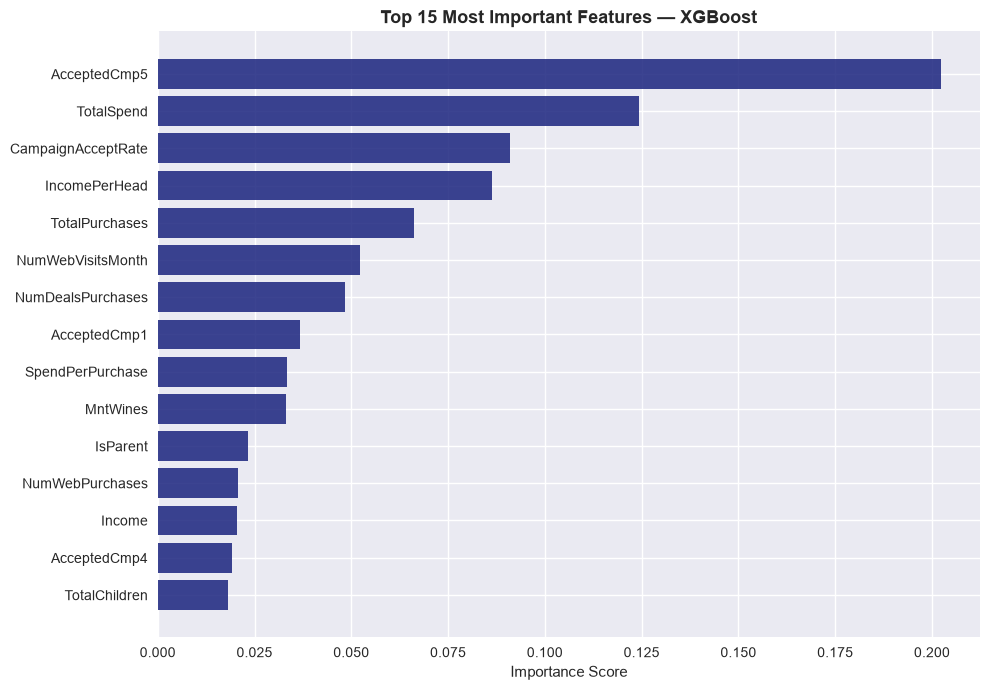

Top 10 features:
  AcceptedCmp5                   0.2023
  TotalSpend                     0.1244
  CampaignAcceptRate             0.0911
  IncomePerHead                  0.0865
  TotalPurchases                 0.0663
  NumWebVisitsMonth              0.0522
  NumDealsPurchases              0.0485
  AcceptedCmp1                   0.0368
  SpendPerPurchase               0.0334
  MntWines                       0.0331


In [24]:
# Feature Importance
feat_imp = pd.DataFrame({
    'feature':    X_train.columns,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(10, 7))
plt.barh(feat_imp['feature'], feat_imp['importance'],
         color='#1a237e', alpha=0.85)
plt.xlabel('Importance Score')
plt.title('Top 15 Most Important Features — XGBoost',
          fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Top 10 features:")
for _, row in feat_imp.head(10).iterrows():
    print(f"  {row['feature']:<30} {row['importance']:.4f}")

Computing SHAP values...


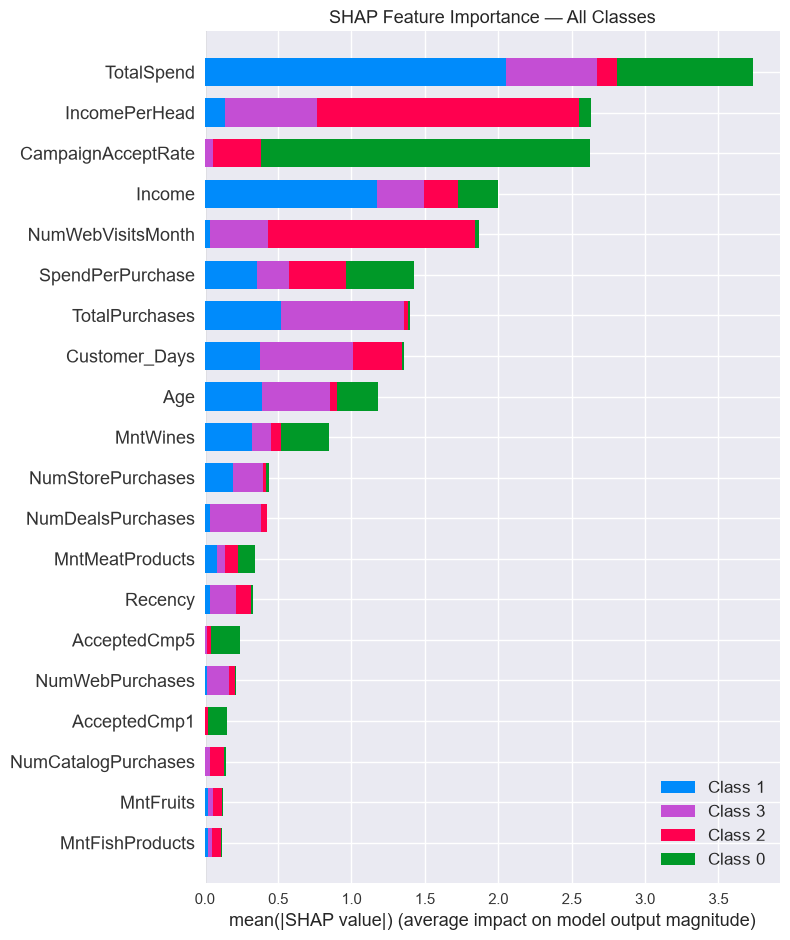

In [25]:
# ═══════════════════════════════════════════════════
# SECTION 9 — SHAP EXPLAINABILITY
# ═══════════════════════════════════════════════════

import shap

print("Computing SHAP values...")
explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_val)

# Summary plot
shap.summary_plot(shap_values, X_val,
                  plot_type='bar', show=False)
plt.title('SHAP Feature Importance — All Classes',
          fontsize=13)
plt.tight_layout()
plt.show()

In [26]:
# ═══════════════════════════════════════════════════
# SECTION 10 — SAVE MODEL AND PREPROCESSORS
# ═══════════════════════════════════════════════════

import pickle
import os

os.makedirs('../models', exist_ok=True)

artifacts = {
    'model':           xgb_model,
    'imputer':         imputer,
    'encoders':        encoders,
    'scaler_cluster':  scaler_cluster,
    'cluster_names':   CLUSTER_NAMES,
    'features':        X_train.columns.tolist(),
    'cluster_features': cluster_features,
}

with open('../models/customer_model.pkl', 'wb') as f:
    pickle.dump(artifacts, f)

print("Model saved to models/customer_model.pkl")
print(f"\nArtifacts saved:")
print(f"  XGBoost classifier")
print(f"  Imputer")
print(f"  Label encoders ({len(encoders)} columns)")
print(f"  KMeans scaler")
print(f"  Cluster names mapping")
print(f"  Feature list ({len(X_train.columns)} features)")

Model saved to models/customer_model.pkl

Artifacts saved:
  XGBoost classifier
  Imputer
  Label encoders (2 columns)
  KMeans scaler
  Cluster names mapping
  Feature list (33 features)


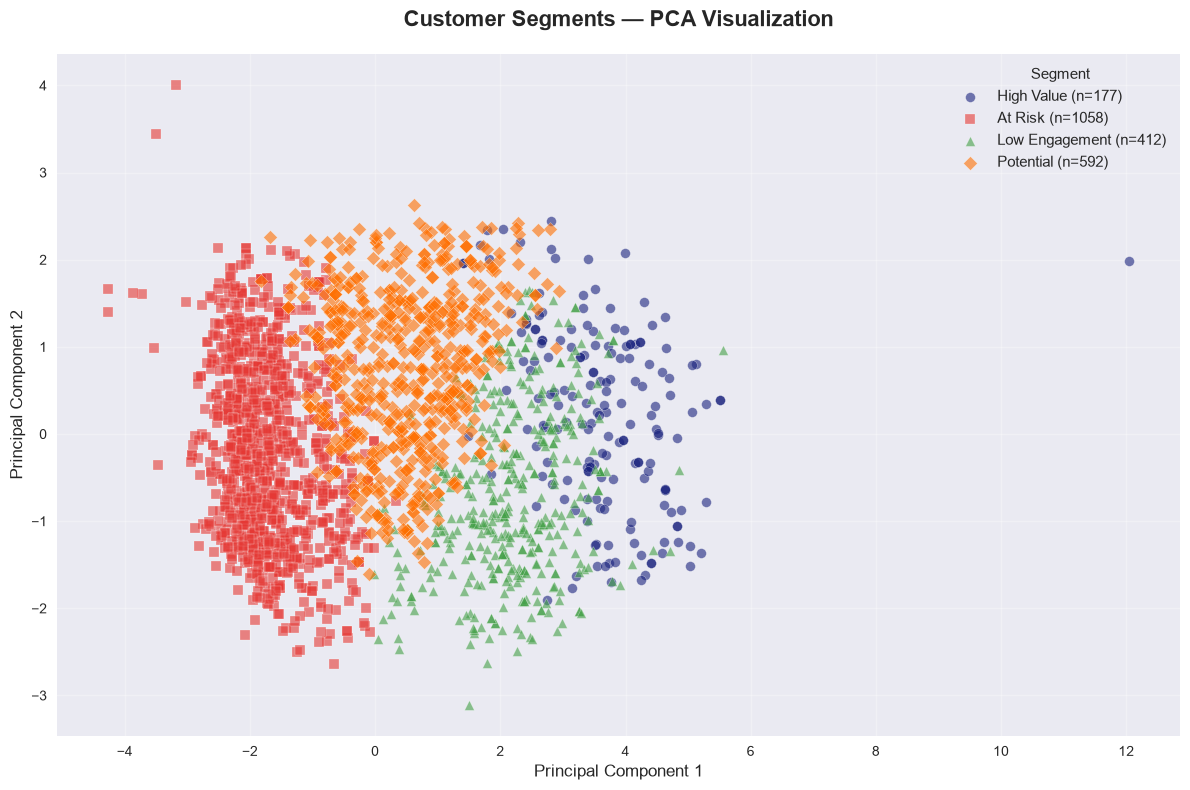

Saved: 01_pca_clusters.png


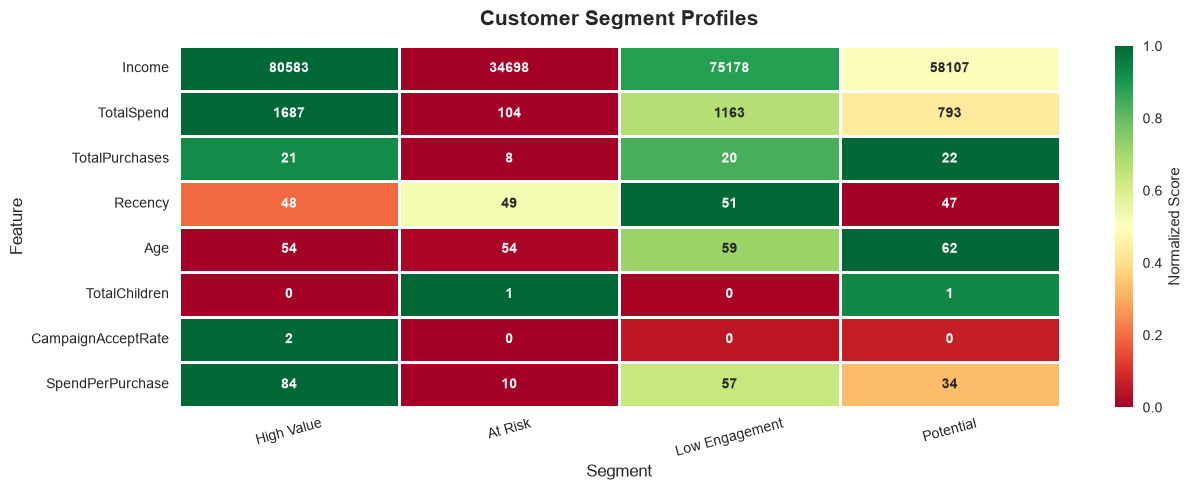

Saved: 02_cluster_heatmap.png


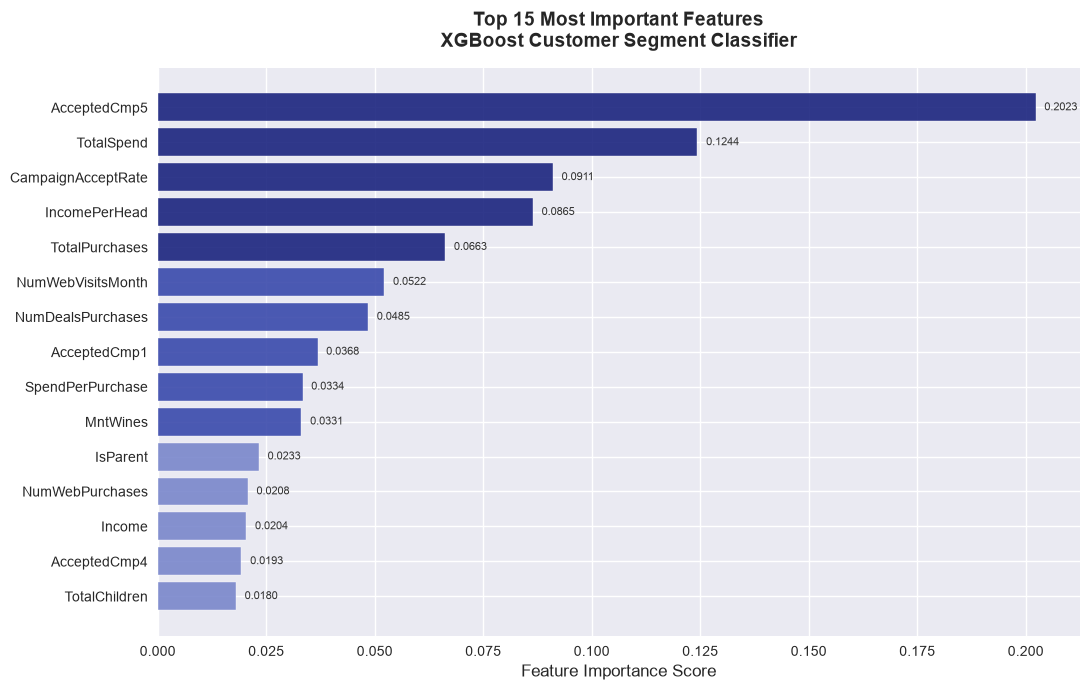

Saved: 03_feature_importance.png


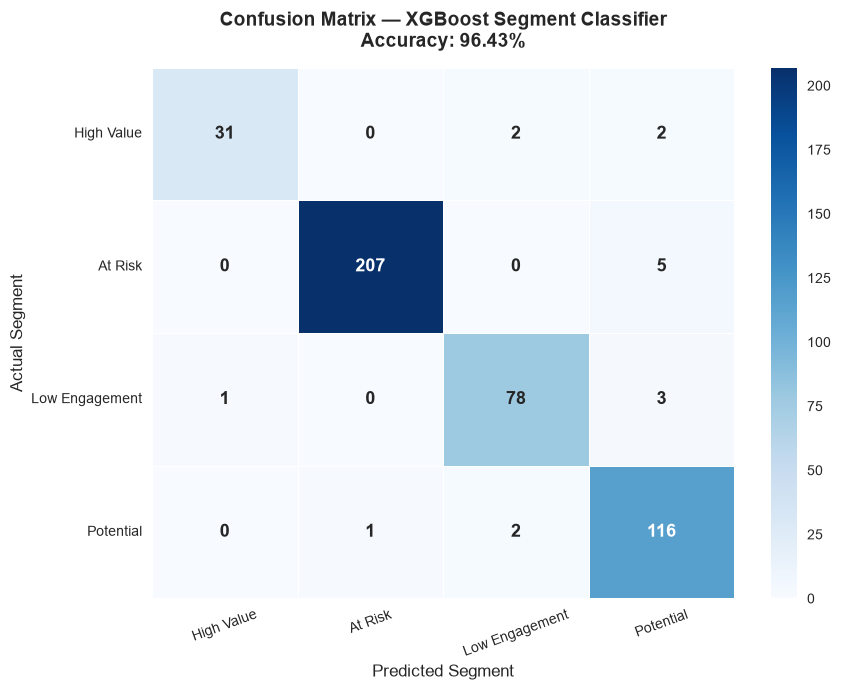

Saved: 04_confusion_matrix.png


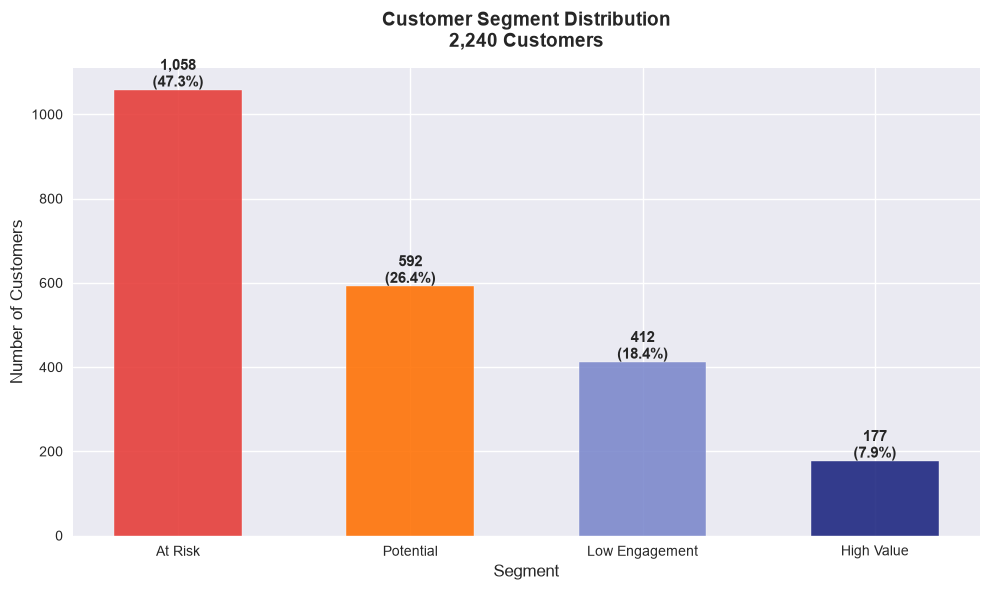

Saved: 05_segment_distribution.png

ALL VISUALS SAVED TO ../visuals/
  01_pca_clusters.png  (306 KB)
  02_cluster_heatmap.png  (83 KB)
  03_feature_importance.png  (90 KB)
  04_confusion_matrix.png  (66 KB)
  05_segment_distribution.png  (52 KB)

LinkedIn Carousel Order:
  1. 01_pca_clusters.png        ← Lead image — stops the scroll
  2. 02_cluster_heatmap.png     ← Business meaning of each segment
  3. 05_segment_distribution.png← Segment sizes — 80/20 insight
  4. 03_feature_importance.png  ← Technical credibility
  5. 04_confusion_matrix.png    ← 96.43% accuracy proof



In [27]:
# ═══════════════════════════════════════════════════
# SAVE ALL KEY VISUALIZATIONS FOR LINKEDIN
# ═══════════════════════════════════════════════════

import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Create visuals folder
os.makedirs('../visuals', exist_ok=True)

# ── IMAGE 1 — PCA CLUSTER VISUALIZATION ─────────────
plt.figure(figsize=(12, 8))
colors  = ['#1a237e', '#e53935', '#43a047', '#ff6f00']
markers = ['o', 's', '^', 'D']

for cluster_id, name in CLUSTER_NAMES.items():
    mask = df['Cluster'] == cluster_id
    plt.scatter(df[mask]['PCA1'], df[mask]['PCA2'],
                c=colors[cluster_id],
                marker=markers[cluster_id],
                label=f'{name} (n={mask.sum()})',
                alpha=0.6, s=50,
                edgecolors='white', linewidths=0.3)

plt.title('Customer Segments — PCA Visualization',
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel(f'Principal Component 1',
           fontsize=12)
plt.ylabel(f'Principal Component 2',
           fontsize=12)
plt.legend(fontsize=11, title='Segment',
           title_fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../visuals/01_pca_clusters.png',
            dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print("Saved: 01_pca_clusters.png")


# ── IMAGE 2 — CLUSTER PROFILE HEATMAP ───────────────
profile_cols = ['Income', 'TotalSpend', 'TotalPurchases',
                'Recency', 'Age', 'TotalChildren',
                'CampaignAcceptRate', 'SpendPerPurchase']

cluster_profile = df.groupby('Cluster')[profile_cols].mean().round(2)
cluster_profile.index = [CLUSTER_NAMES[i]
                          for i in cluster_profile.index]

# Normalize for color scaling
profile_norm = (cluster_profile - cluster_profile.min()) / \
               (cluster_profile.max() - cluster_profile.min())

plt.figure(figsize=(13, 5))
sns.heatmap(profile_norm.T,
            annot=cluster_profile.T,
            fmt='.0f',
            cmap='RdYlGn',
            linewidths=0.8,
            linecolor='white',
            annot_kws={'size': 10, 'weight': 'bold'},
            cbar_kws={'label': 'Normalized Score'})
plt.title('Customer Segment Profiles',
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Segment', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.xticks(fontsize=10, rotation=15)
plt.yticks(fontsize=10, rotation=0)
plt.tight_layout()
plt.savefig('../visuals/02_cluster_heatmap.png',
            dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print("Saved: 02_cluster_heatmap.png")


# ── IMAGE 3 — FEATURE IMPORTANCE ────────────────────
feat_imp = pd.DataFrame({
    'feature':    X_train.columns,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(11, 7))
colors_imp = ['#1a237e' if i < 5 else
              '#3949ab' if i < 10 else
              '#7986cb'
              for i in range(len(feat_imp))]

bars = plt.barh(feat_imp['feature'],
                feat_imp['importance'],
                color=colors_imp,
                alpha=0.9,
                edgecolor='white')
plt.xlabel('Feature Importance Score', fontsize=12)
plt.title('Top 15 Most Important Features\nXGBoost Customer Segment Classifier',
          fontsize=14, fontweight='bold', pad=15)
plt.gca().invert_yaxis()

for bar, val in zip(bars, feat_imp['importance']):
    plt.text(val + 0.002,
             bar.get_y() + bar.get_height()/2,
             f'{val:.4f}',
             va='center', fontsize=8,
             color='#333333')

plt.tight_layout()
plt.savefig('../visuals/03_feature_importance.png',
            dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print("Saved: 03_feature_importance.png")


# ── IMAGE 4 — CONFUSION MATRIX ───────────────────────
cm = confusion_matrix(y_val, y_pred)
segment_labels = [CLUSTER_NAMES[i]
                  for i in sorted(CLUSTER_NAMES.keys())]

plt.figure(figsize=(9, 7))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=segment_labels,
            yticklabels=segment_labels,
            linewidths=0.5,
            linecolor='white',
            annot_kws={'size': 13, 'weight': 'bold'})
plt.title('Confusion Matrix — XGBoost Segment Classifier\nAccuracy: 96.43%',
          fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Actual Segment', fontsize=12)
plt.xlabel('Predicted Segment', fontsize=12)
plt.xticks(fontsize=10, rotation=20)
plt.yticks(fontsize=10, rotation=0)
plt.tight_layout()
plt.savefig('../visuals/04_confusion_matrix.png',
            dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print("Saved: 04_confusion_matrix.png")


# ── IMAGE 5 — SEGMENT SIZE BAR CHART ─────────────────
segment_counts = df['Segment'].value_counts()
colors_seg     = ['#e53935', '#ff6f00', '#7986cb', '#1a237e']

plt.figure(figsize=(10, 6))
bars = plt.bar(segment_counts.index,
               segment_counts.values,
               color=colors_seg,
               alpha=0.88,
               edgecolor='white',
               width=0.55)
plt.title('Customer Segment Distribution\n2,240 Customers',
          fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Number of Customers', fontsize=12)
plt.xlabel('Segment', fontsize=12)

for bar, val in zip(bars, segment_counts.values):
    pct = val / len(df) * 100
    plt.text(bar.get_x() + bar.get_width()/2,
             val + 8,
             f'{val:,}\n({pct:.1f}%)',
             ha='center', fontweight='bold',
             fontsize=11)

plt.tight_layout()
plt.savefig('../visuals/05_segment_distribution.png',
            dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print("Saved: 05_segment_distribution.png")


# ── FINAL SUMMARY ────────────────────────────────────
print("\n" + "=" * 50)
print("ALL VISUALS SAVED TO ../visuals/")
print("=" * 50)
for f in sorted(os.listdir('../visuals')):
    size = os.path.getsize(f'../visuals/{f}') / 1024
    print(f"  {f}  ({size:.0f} KB)")

print("""
LinkedIn Carousel Order:
  1. 01_pca_clusters.png        ← Lead image — stops the scroll
  2. 02_cluster_heatmap.png     ← Business meaning of each segment
  3. 05_segment_distribution.png← Segment sizes — 80/20 insight
  4. 03_feature_importance.png  ← Technical credibility
  5. 04_confusion_matrix.png    ← 96.43% accuracy proof
""")